# X5 RetailHero uplift: exploratory data analysis

All numbers below are computed by `eda/x5_eda_lib.py` from the input files of this run; nothing is typed in by hand.
**Read the mode banner first**: a `sample` run describes the 1% client sample, a `full` run describes every row of the
five tables. Sample statistics must never be quoted as full-data results.

Sections: 1 files and keys, 2 timestamps, 3 campaign cutoff / leakage, 4 treatment and outcome, 5 distributions,
6 uplift by segment, 7 ID formats, 8 `uplift_test`, 9 clients without purchases and unmatched IDs, 10 transaction semantics.

In [1]:
# ruff: noqa: E402
import os
import sys
from pathlib import Path

root = Path.cwd().resolve()
while not (root / "configs" / "x5" / "eda.yaml").exists():
    if root.parent == root:
        raise RuntimeError("run this notebook from inside the repository")
    root = root.parent
sys.path.insert(0, str(root))

import pandas as pd
from IPython.display import Image, display

from eda.x5_eda_lib import EdaSettings, flatten, run_eda
from ingestion.x5_common import load_config

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.6g}")

# ---- parameters (override with environment variables) -------------------------------------------
MODE = os.environ.get("X5_EDA_MODE", "sample")  # "sample" or "full"
INPUT_DIR = os.environ.get("X5_EDA_INPUT_DIR") or None  # default: eda.input_dirs.<mode> in configs/x5/eda.yaml
CUTOFF = os.environ.get("X5_CAMPAIGN_CUTOFF") or None  # default: campaign.cutoff (null: unknown)
OUTPUT_DIR = os.environ.get("X5_EDA_OUTPUT_DIR") or None  # default: eda.output_root/<mode>
FORCE_REBUILD = os.environ.get("X5_EDA_FORCE") == "1"

In [2]:
config = load_config(root / "configs" / "x5" / "eda.yaml")
settings = EdaSettings.from_config(config, mode=MODE, input_dir=INPUT_DIR, output_dir=OUTPUT_DIR, cutoff=CUTOFF)
res = run_eda(settings, force=FORCE_REBUILD, figures=True, log=lambda *_: None)
R = res.sections
FIG = settings.output_dir / "figures"


def show_fig(name):
    path = FIG / name
    display(Image(filename=str(path))) if path.exists() else print(f"(figure {name} not produced)")


banner = R["run"]["mode_description"]
print("MODE:", MODE.upper())
print(banner)
print("input directory:", R["run"]["input_dir"])
display(pd.DataFrame(R["run"]["input_files"]).T)
if "sample_metadata" in R["run"]:
    display(flatten(R["run"]["sample_metadata"]))

MODE: FULL
FULL data: every row of the five X5 tables
input directory: /Users/ameyakhond/Desktop/DATA 298A/project/data/x5/extracted


,file,bytes
clients,clients.csv,21736219
uplift_train,uplift_train.csv,3000616
uplift_test,uplift_test.csv,2201363
products,products.csv,3890339
purchases,purchases.csv,4463775504


## 1. File statistics, nulls, duplicates and key checks

In [3]:
files = R["files"]
display(
    pd.DataFrame(
        {
            t: {"rows": files[f"{t}_rows"], "columns": len(files[f"{t}_columns"])}
            for t in ["clients", "uplift_train", "uplift_test", "products", "purchases"]
        }
    ).T
)
print(
    "values that failed to cast to their target type (should be 0 unless the data are dirty):",
    files["cast_failures_total"],
)
display(
    res.tables["cast_failures"].query("n_failed > 0")
    if (res.tables["cast_failures"]["n_failed"] > 0).any()
    else "no cast failures"
)
nulls = res.tables["null_counts"]
display(nulls[nulls["n_null"] > 0] if (nulls["n_null"] > 0).any() else "no null values in any column")
display(pd.DataFrame(files["key_uniqueness"]).T)
display(flatten(files["purchases"]))

,rows,columns
clients,400162,5
uplift_train,200039,3
uplift_test,200123,1
products,43038,11
purchases,45786568,13


values that failed to cast to their target type (should be 0 unless the data are dirty): 0


'no cast failures'

,table,column,n_rows,n_null,null_share
2,clients,first_redeem_ts,400162,35469,0.0886366
10,products,level_1,43038,3,6.97058e-05
11,products,level_2,43038,3,6.97058e-05
12,products,level_3,43038,3,6.97058e-05
13,products,level_4,43038,3,6.97058e-05
14,products,segment_id,43038,1572,0.0365259
15,products,brand_id,43038,5200,0.120823
16,products,vendor_id,43038,34,0.00079
17,products,netto,43038,3,6.97058e-05
30,purchases,trn_sum_from_red,45786568,42743212,0.933532


,key,rows_with_key,distinct_keys,duplicate_rows
clients,client_id,400162,400162,0
uplift_train,client_id,200039,200039,0
uplift_test,client_id,200123,200123,0
products,product_id,43038,43038,0


,key,value
0,rows,45786568
1,exact_duplicate_rows_hash_based,0
2,rows_beyond_first_per_transaction_product_pair,3
3,distinct_transaction_id,8045201
4,distinct_client_transaction_pairs,8045229
5,distinct_client_id,400162
6,distinct_product_id,42530
7,distinct_store_id,13882


## 2. Timestamp range and invalid timestamps

,key,value
0,purchase_ts_min,2018-11-21 21:02:33
1,purchase_ts_max,2019-03-18 23:40:03
2,purchase_rows,45786568
3,purchase_ts_null_or_invalid_rows,0
4,purchase_ts_unparseable_non_null_values,0
5,timezone_note,timestamps are naive local retail time as publ...
6,purchase_span_days,117.109
7,clients_first_issue_ts_min,2017-04-04 18:24:18
8,clients_first_issue_ts_max,2019-03-15 21:50:56
9,clients_first_redeem_ts_min,2017-04-11 09:42:20


,month,n_transactions,n_clients,spend,first_ts,last_ts
0,2018-11,553288,223449,2.24938e+08,2018-11-21 21:02:33,2018-11-30 23:54:28
1,2018-12,1979356,329130,8.8017e+08,2018-12-01 00:12:12,2018-12-31 19:41:47
2,2019-01,1908118,331791,7.94009e+08,2019-01-01 07:15:17,2019-01-31 23:59:18
3,2019-02,2104788,360005,8.85825e+08,2019-02-01 00:08:32,2019-02-28 23:59:08
4,2019-03,1499679,377847,6.59452e+08,2019-03-01 00:15:26,2019-03-18 23:40:03


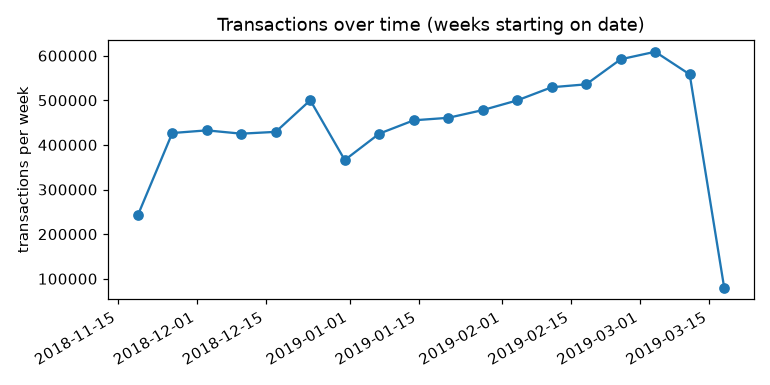

In [4]:
display(flatten(R["timestamps"]))
display(res.tables["transactions_by_month"])
show_fig("transactions_over_time.png")

## 3. Campaign cutoff and leakage

The dataset publishes **no campaign date**. While `campaign.cutoff` is unset this check is reported as `blocked`,
not as passed, and the recency anchor is the provisional maximum purchase timestamp.

In [5]:
display(flatten(R["leakage"]))

,key,value
0,recency_anchor,2019-03-18 23:40:03
1,recency_anchor_label,PROVISIONAL: max purchase timestamp (campaign ...
2,status,blocked
3,reason,campaign.cutoff is not set: no campaign date i...


## 4. Treatment and outcome

,treatment_flg,n,conversions,rate
0,0,100058,"60,363",0.60328
1,1,99981,"63,639",0.636511


,treated vs control
n,200039
n_treated,99981
n_control,100058
conversions_treated,63639
conversions_control,60363
rate_treated,0.636511
rate_control,0.60328
uplift,0.0332308
se,0.00216934
ci_low,0.028979


treated share: 0.4998075375301816  vs 0.5:  {'z': -0.17216044944188358, 'p_value': 0.8633113903439604}


,covariate,mean_control,mean_treated,n_control,n_treated,smd
0,age_valid,46.4817,46.5822,99301,99162,0.00636604
1,gender_female,0.367637,0.36918,100058,99981,0.00319953
2,gender_male,0.167763,0.167282,100058,99981,-0.00128778
3,gender_unknown,0.464601,0.463538,100058,99981,-0.00213042
4,tenure_days,432.702,434.444,100058,99981,0.00855048
5,has_purchases,1,1,100058,99981,NaN
6,n_transactions,20.0561,20.1856,100058,99981,0.00730303
7,total_spend,"8,569.37","8,625.7",100058,99981,0.00631925
8,recency_days,6.30139,6.30042,100058,99981,-0.000170548
9,n_stores,2.91734,2.92405,100058,99981,0.00334508


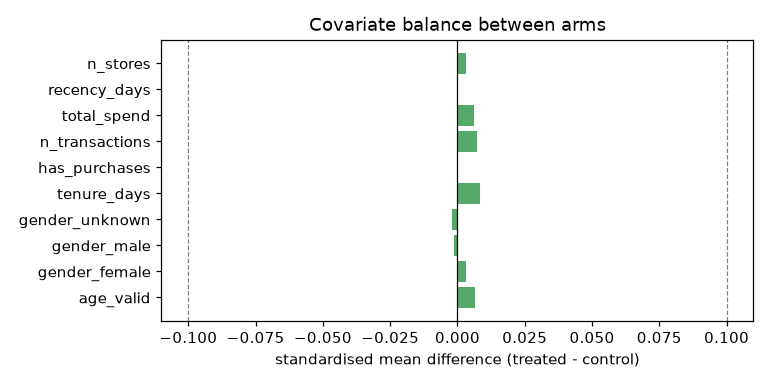

In [6]:
t = R["treatment"]
display(res.tables["treatment_outcome"])
display(pd.DataFrame([t["overall"]]).T.rename(columns={0: "treated vs control"}))
print("treated share:", t["treated_share"], " vs 0.5: ", t["share_vs_half"])
display(res.tables["covariate_balance"])
show_fig("covariate_balance.png")

## 5. Distributions

,n_rows,n_non_null,mean,std,min,max,n_negative,n_zero,n_positive,q0.001,q0.01,q0.05,q0.25,q0.5,q0.75,q0.95,q0.99,q0.999
spend_per_transaction,8.04523e+06,8.04523e+06,428.129,488.814,0,"35,149",0,567,8.04466e+06,6.59,23,47,140,282,533.71,"1,297","2,372.07","4,471.95"
transactions_per_client_with_purchases,"400,162","400,162",20.1049,17.7292,1,320,0,0,"400,162",1,1,3,8,15,27,54,85,137
total_spend_per_client_with_purchases,"400,162","400,162","8,607.5","8,952.02",1.04,"525,338",0,0,"400,162",64,297,946.345,"3,146.66","6,111.35","11,101.9","24,247.1","41,946.3","78,795.5"
recency_days_with_purchases,"400,162","400,162",6.31126,5.67812,0,22.092,0,1,"400,161",0.169624,0.239447,0.351944,1.55614,4.41306,9.57889,18.3911,21.3304,21.6824
stores_per_client_with_purchases,"400,162","400,162",2.92343,1.99792,1,95,0,0,"400,162",1,1,1,1,2,4,7,10,15
product_rows_per_transaction,8.04523e+06,8.04523e+06,5.69115,5.00303,1,116,0,0,8.04523e+06,1,1,1,2,4,7,15,24,39
tenure_days_at_anchor,"400,162","400,162",433.259,203.605,3.07578,713.219,0,0,"400,162",7.19578,16.6132,58.3429,271.23,487.353,605.157,671.192,700.237,707.207
age_all_values,"400,162","400,162",46.4881,43.8712,"-7,491","1,901",96,42,"400,024",10,17,22,34,45,59,72,82,119
age_valid_range,"396,972","396,972",46.5316,15.7908,16,100,0,0,"396,972",16,18,22,34,45,59,72,81,87
quantity_per_row,4.57866e+07,4.57866e+07,1.24724,3.13758,0,"14,941",0,2.70728e+06,4.30793e+07,0,0,0,1,1,1,3,5,11


ages outside the valid range [16, 100] : {'below_min': 2141, 'above_max': 1049, 'null': 0}


,gender,n_clients,n_without_purchases,share
0,F,147649,0,0.368973
1,M,66807,0,0.16695
2,U,185706,0,0.464077


,column,n_transactions,n_non_null,min,max,n_negative,n_zero,n_positive,mean
0,regular_points_received,8045229,8045229,0,"2,399",0,150547,7894682,3.88242
1,express_points_received,8045229,8045229,0,300,0,8037815,7414,0.039749
2,regular_points_spent,8045229,8045229,"-5,066",0,495331,7549898,0,-3.6514
3,express_points_spent,8045229,8045229,-300,0,90469,7954760,0,-0.319278


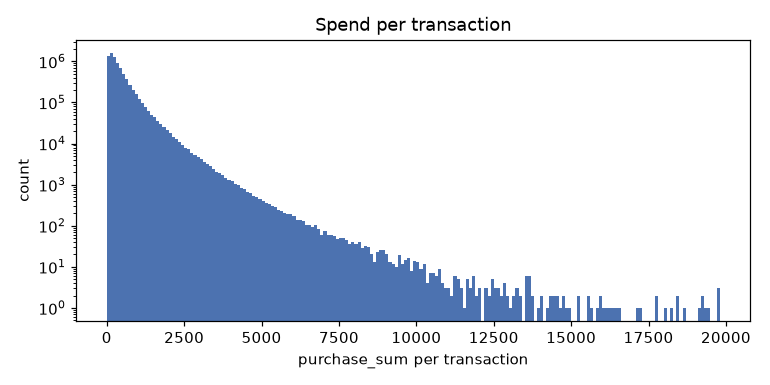

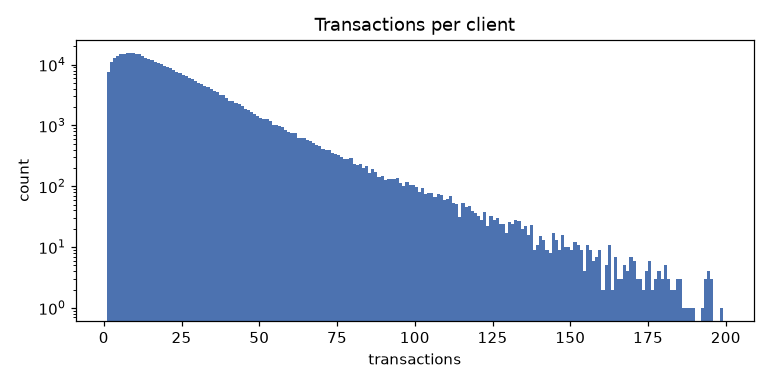

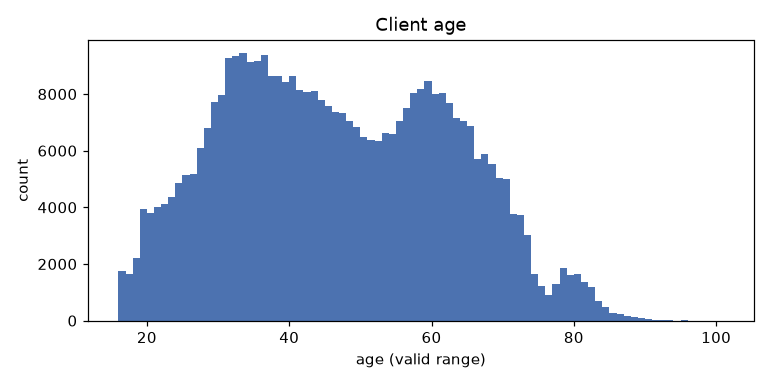

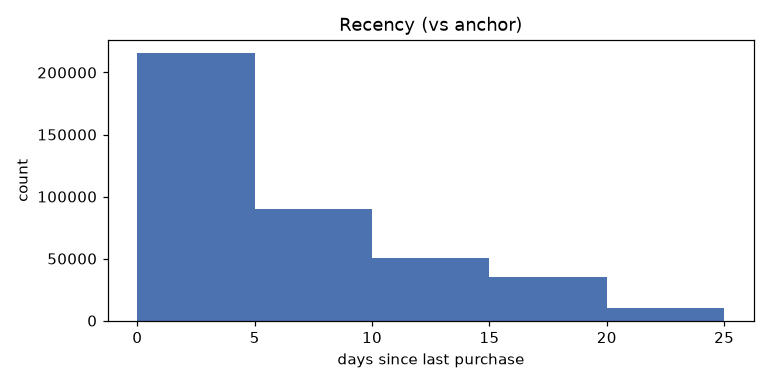

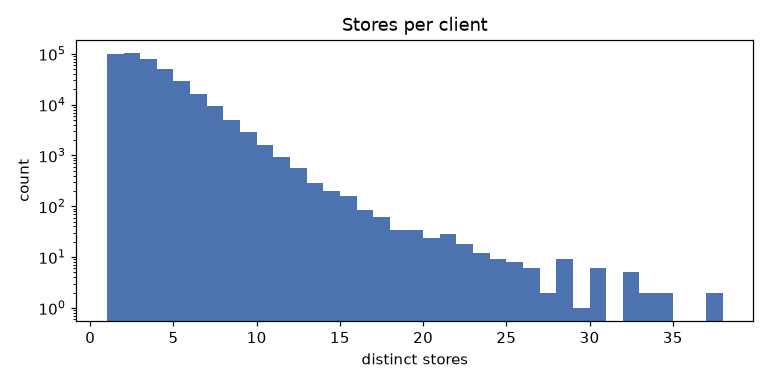

In [7]:
d = R["distributions"]
names = [
    "spend_per_transaction",
    "transactions_per_client_with_purchases",
    "total_spend_per_client_with_purchases",
    "recency_days_with_purchases",
    "stores_per_client_with_purchases",
    "product_rows_per_transaction",
    "tenure_days_at_anchor",
    "age_all_values",
    "age_valid_range",
    "quantity_per_row",
]
rows = []
for n in names:
    row = {k: v for k, v in d[n].items() if k != "quantiles"}
    row.update({f"q{q}": v for q, v in d[n]["quantiles"].items()})
    rows.append(pd.Series(row, name=n))
display(pd.DataFrame(rows))
print("ages outside the valid range", d["valid_age_range"], ":", d["age_outside_valid_range"])
display(res.tables["gender_counts"])
display(res.tables["points_sign_conventions"])
for fig in [
    "spend_per_transaction.png",
    "transactions_per_client.png",
    "age.png",
    "recency_days.png",
    "stores_per_client.png",
]:
    show_fig(fig)

## 6. Uplift by segment

Segments use client attributes and purchase history only (never the outcome). Segments flagged `sparse` have an arm with
fewer than `eda.min_arm_size` clients or a treatment x outcome cell with fewer than `eda.min_cell_events` clients; their
intervals are unreliable. Intervals are Wald 95% intervals; no multiplicity correction is applied across segments.

,key,value
0,age_band,"client age in [16, 100] split at [16, 25, 35, ..."
1,recency_band,days from last purchase to the recency anchor ...
2,spend_tier,client total spend (sum of purchase_sum once p...
3,caveat,purchase history may extend past the campaign ...


,segment_kind,segment,n,n_treated,n_control,rate_treated,rate_control,uplift,ci_low,ci_high,p_value,sparse
0,age_band,016-024,15265,7645,7620,0.596861,0.583465,0.0133961,-0.00220599,0.0289982,0.0924052,False
1,age_band,025-034,38113,18909,19204,0.601089,0.585243,0.0158468,0.00598433,0.0257092,0.00163701,False
2,age_band,035-044,42458,21122,21336,0.623331,0.592754,0.0305771,0.0212947,0.0398595,1.07309e-10,False
3,age_band,045-054,34262,17206,17056,0.630536,0.59674,0.0337957,0.0234899,0.0441015,1.29914e-10,False
4,age_band,055-064,38610,19342,19268,0.659342,0.619265,0.0400773,0.0305056,0.0496489,2.27619e-16,False
5,age_band,065-100,29755,14938,14817,0.701633,0.64264,0.0589932,0.0483454,0.069641,1.80639e-27,False
6,age_band,invalid_or_missing,1576,819,757,0.562882,0.527081,0.035801,-0.0133822,0.0849842,0.153672,False
7,gender,F,73696,36911,36785,0.660697,0.620443,0.0402542,0.0333316,0.0471769,4.33396e-30,False
8,gender,M,33511,16725,16786,0.636114,0.606815,0.0292984,0.0189173,0.0396795,3.17351e-08,False
9,gender,U,92832,46345,46487,0.617391,0.588423,0.0289687,0.0226765,0.035261,1.8231e-19,False


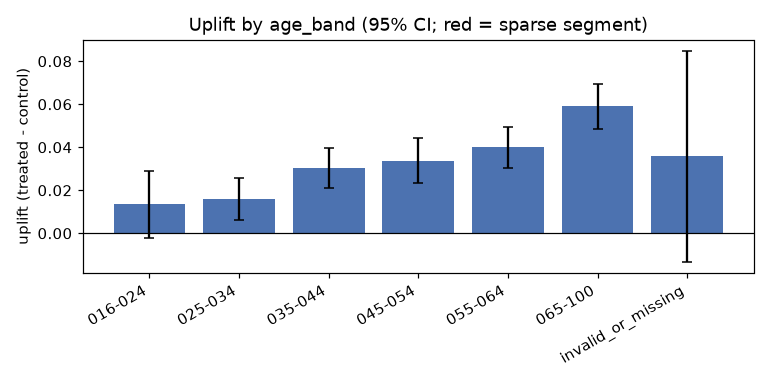

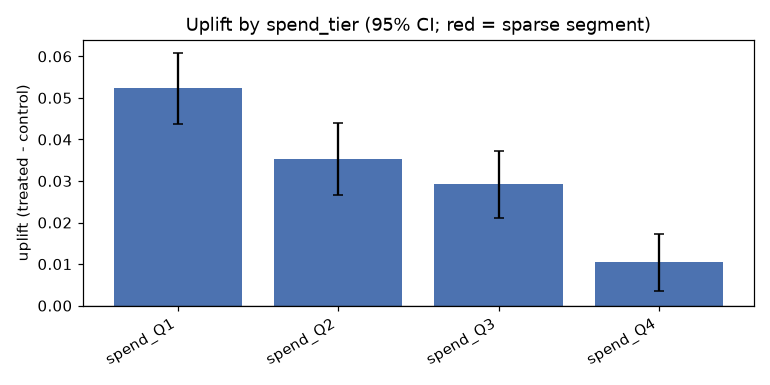

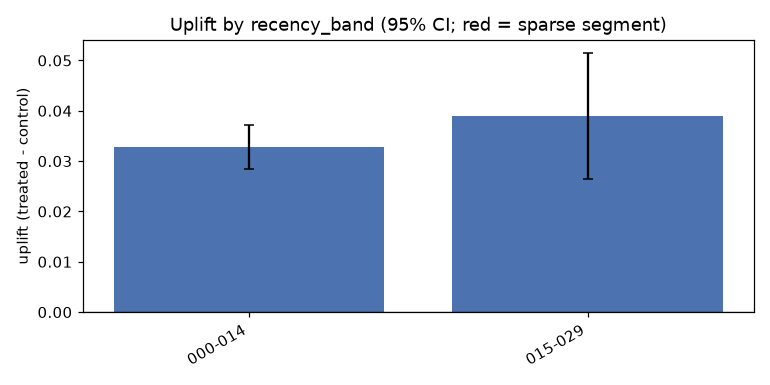

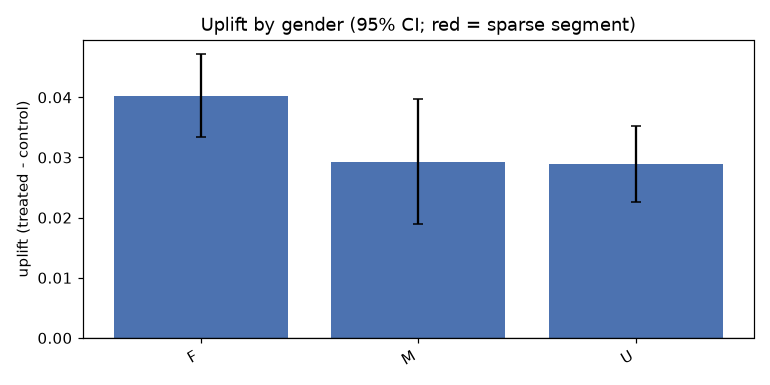

In [8]:
seg = res.tables["uplift_by_segment"]
display(flatten(R["segments"]["definitions"]))
display(
    seg[
        [
            "segment_kind",
            "segment",
            "n",
            "n_treated",
            "n_control",
            "rate_treated",
            "rate_control",
            "uplift",
            "ci_low",
            "ci_high",
            "p_value",
            "sparse",
        ]
    ]
)
for kind in ["age_band", "spend_tier", "recency_band", "gender"]:
    show_fig(f"uplift_by_{kind}.png")

## 7. Product, category and ID formats (observed vs hashed)

In [9]:
display(res.tables["id_formats"])
display(flatten({k: v for k, v in R["id_formats"].items()}))

,table,column,distinct_values,min_length,max_length,share_lowercase_hex,share_digits_only,share_leading_zero,n_blank_or_padded,n_scientific_notation_like
0,clients,client_id,400162,10,10,1,0.00897387,0.0623472,0,2967
1,uplift_train,client_id,200039,10,10,1,0.00906823,0.0625128,0,1511
2,uplift_test,client_id,200123,10,10,1,0.00887954,0.0621818,0,1456
3,products,product_id,43038,10,10,1,0.00843441,0.0629211,0,299
4,products,level_1,3,10,10,1,0,0,0,0
5,products,level_2,42,10,10,1,0,0.0238095,0,0
6,products,level_3,201,10,10,1,0.00497512,0.0646766,0,2
7,products,level_4,790,10,10,1,0.0101266,0.0582278,0,4
8,products,brand_id,4296,10,10,1,0.0104749,0.0544693,0,32
9,products,vendor_id,3193,10,10,1,0.0106483,0.0682744,0,27


,key,value
0,products_segment_id_non_null,41466
1,products_segment_id_integer_valued_floats,41466
2,interpretation,IDs are opaque strings. Columns whose distinct...


## 8. `uplift_test`: does it carry labels?

In [10]:
display(flatten(R["uplift_test"]))

,key,value
0,columns,[client_id]
1,label_columns_present,[]
2,has_labels,False
3,clients,200123
4,clients_with_purchases,200123
5,note,uplift_test has no outcome or treatment column...


## 9. Clients without purchases and unmatched IDs

In [11]:
display(pd.DataFrame([R["files"]["relationships"]]).T.rename(columns={0: "count"}))
display(res.tables["clients_without_purchases"])

,count
train_clients_not_in_clients,0
test_clients_not_in_clients,0
train_test_overlap_clients,0
clients_in_neither_train_nor_test,0
purchase_clients_not_in_clients,0
purchase_rows_with_client_not_in_clients,0
purchase_product_ids_not_in_products,0
purchase_rows_with_product_not_in_products,0
purchase_rows_with_null_product_id,0
products_never_purchased,508


,population,treatment_flg,n_clients,n_without_purchases,share_without_purchases
0,uplift_test,<NA>,200123,0,0
1,uplift_train,0,100058,0,0
2,uplift_train,1,99981,0,0


## 10. Transaction semantics

`purchase_sum` and the points columns repeat on every product row of a transaction, so summing them per row overstates
spend. These checks quantify that, test the grouping key, and compare `trn_sum_from_iss` / `trn_sum_from_red` with
`purchase_sum`.

In [12]:
sem = R["semantics"]
display(
    flatten(
        {
            k: v
            for k, v in sem.items()
            if k
            not in (
                "line_amount_vs_purchase_sum",
                "sum_iss_over_purchase_sum_quantiles",
                "sum_iss_relative_agreement_with_purchase_sum",
                "interpretation",
            )
        }
    )
)
display(flatten(sem["line_amount_vs_purchase_sum"]))
display(flatten(sem["sum_iss_relative_agreement_with_purchase_sum"]))
display(flatten(sem["sum_iss_over_purchase_sum_quantiles"]))
display(flatten(sem["interpretation"]))
display(res.tables["rows_per_transaction"])

,key,value
0,transactions,8045229
1,transactions_definition,"distinct (client_id, transaction_id) pairs"
2,product_rows,45786568
3,transactions_with_several_rows,6977760
4,transactions_with_one_row,1067469
5,multi_row_transactions_where_value_differs_bet...,0
6,multi_row_transactions_where_value_differs_bet...,0
7,multi_row_transactions_where_value_differs_bet...,0
8,multi_row_transactions_where_value_differs_bet...,0
9,multi_row_transactions_where_value_differs_bet...,0


,key,value
0,transactions_with_iss,8.04523e+06
1,transactions_with_red,"506,236"
2,sum_iss_equals_purchase_sum,1.57498e+06
3,sum_iss_plus_red_equals_purchase_sum,1.58099e+06
4,sum_iss_above_purchase_sum,4.56136e+06
5,sum_iss_below_purchase_sum,1.84877e+06
6,transactions_without_any_iss,0
7,tolerance,0.01


,key,value
0,transactions_compared,8044662
1,within_1e-6,1446861
2,within_1pct,6647775
3,within_5pct,7379624
4,within_10pct,7503719


,key,value
0,0.01,0.243902
1,0.05,0.810423
2,0.25,1
3,0.5,1.00023
4,0.75,1.0029
5,0.95,1.0137
6,0.99,1.03226


,key,value
0,purchase_sum_and_points_are_transaction_level,True
1,rule,aggregate purchase_sum and the four points col...


,product_rows_capped_at_10,n_transactions
0,1,1067469
1,2,1213203
2,3,1082113
3,4,892175
4,5,727430
5,6,588138
6,7,474189
7,8,379762
8,9,305139
9,10,1315611


## Output locations

Tables, figures and `summary.json` for this run are in `eda/outputs/<mode>/` (git-ignored). `eda/FINDINGS.md` is generated from
the `full` outputs only.

In [13]:
print("outputs:", settings.output_dir)
print("stage seconds:", R["run"]["stage_seconds"])

outputs: /Users/ameyakhond/Desktop/DATA 298A/project/worktrees/x5-eda/eda/outputs/full
stage seconds: {'prepare': 0.001, 'files': 4.191, 'timestamps': 0.585, 'leakage': 0.002, 'distributions': 2.863, 'treatment': 0.232, 'segments': 0.093, 'id_formats': 0.561, 'uplift_test': 0.016, 'semantics': 1.328}
